In [1]:
2+2

4

In [4]:
import os 
import random
import requests
from typing import Annotated
from typing_extensions import TypedDict
from dotenv import load_dotenv
from IPython.display import Image, display
from langchain_openai import ChatOpenAI
from langchain_community.tools import GoogleSerperRun
from langchain_community.utilities import GoogleSerperAPIWrapper
from langchain_core.tools import tool
from langgraph.graph import StateGraph, START ,END
from langgraph.graph.message import add_messages
from langgraph.prebuilt import ToolNode, tools_condition
from langgraph.checkpoint.memory import MemorySaver
#from langgraph.checkpoint.sqlite import SqliteSaver


In [10]:
class State(TypedDict):
    messages: Annotated[list, add_messages]
    

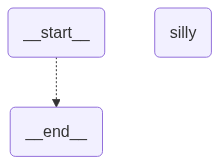

In [11]:
nouns = ["Cabbages", "Unicorns", "Toasters", "Penguins", "Bananas", "Eels", "Pickles"]
adjectives = ["outrageous", "smelly", "pedantic", "existential", "sparkly", "haunted"]

def silly_node(state: State) -> dict:
    sentence = f'{random.choice(nouns)} are {random.choice(adjectives)}'
    return {"messages":[{"role":"assistant","content":sentence}]}

builder = StateGraph(State)
builder.add_node('silly',silly_node)
builder.add_edge(START,END)
builder.add_edge("silly",END)
graph = builder.compile()

display(Image(graph.get_graph().draw_mermaid_png()))

In [12]:
result = graph.invoke({'messages':[{'role':"user","content":"say something"}]})
print(result['messages'][-1].content)

say something


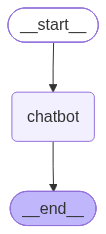

In [13]:
llm = ChatOpenAI(model='gpt-3.5-turbo')

def chatbot_node(state: State) -> dict:
    return{'messages':[llm.invoke(state['messages'])]}

builder = StateGraph(State)
builder.add_node('chatbot',chatbot_node)
builder.add_edge(START,'chatbot')
builder.add_edge('chatbot', END)
graph = builder.compile()

display(Image(graph.get_graph().draw_mermaid_png()))

In [14]:
result=graph.invoke({'messages':[{'role':'user',"content":"what is a directed graph?"}]})
print(result['messages'][-1].content)

A directed graph is a type of graph in which edges have an associated direction, meaning they are directed from one vertex to another. This means that the relationship between nodes is one-way, rather than bidirectional as in an undirected graph. Directed graphs are also known as digraphs and are commonly used in various fields such as computer science, network theory, and mathematics to model relationships and dependencies between different entities.


In [19]:
from langchain_community.tools import DuckDuckGoSearchRun
search=DuckDuckGoSearchRun()
class State(TypedDict):
    messages: Annotated[list, add_messages]
 
llm=ChatOpenAI(model='gpt-3.5-turbo')
tools=[search]
llm_with_tools = llm.bind_tools(tools)

def chatbot_node(state: State) -> dict:
    return {"messages": [llm_with_tools.invoke(state['messages'])]}

builder = StateGraph(State)
builder.add_node("chatbot", chatbot_node)
builder.add_node("tools", ToolNode(tools))
builder.add_edge(START, 'chatbot')
builder.add_conditional_edges('chatbot', tools_condition)
builder.add_edge("tools", "chatbot")
graph = builder.compile()
result=graph.invoke({'messages': [{"role":'user', "content":"what is the function of Reducer in langgraph"}]})
print(result["messages"][-1].content)

A Reducer in LangGraph is a function that takes in multiple inputs, like messages, states, or results from different parts of your graph, and reduces them into a single, unified output. It defines how to update a specific field in your graph's state when a node returns a new value. By default, LangGraph uses a simple "overwrite" reducer. Reducers play a crucial role in controlling how data flows through a graph and are essential for managing state updates and building predictable multi-step workflows.


In [ ]:
class State(TypedDict):
    messages: Annotated[list, add_messages]
    spanish: str


def translator_node(state: State) -> dict:
    last =state['messages'][-1].content
    prompt = f'Translate this into spanish, replying with the translation only :\n\n{last}'
    return {'spanish': llm.invoke(prompt).content}

builder= StateGraph(State)
builder.add_node("chatbot", chatbot_node)
builder.add_node("tools", ToolNode(tools))
builder.add_node("translator", translator_node)
builder.add_edge(START, "chatbot")
builder.add_conditional_edges("chatbot", tools_condition,{"tools":"tools", END:"translator"})
builder.add_edge("tools","chatbot")
builder.add_edge("translator",END)
graph = builder.compile()


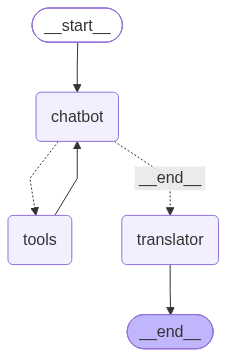

In [21]:
display(Image(graph.get_graph().draw_mermaid_png()))

In [22]:
result=graph.invoke({'messages':[{"role":"user","content":"in one sentence, what is special about banana"}]})
print(result['messages'][-1].content)

Bananas are a popular fruit known for their unique, curved shape, convenient natural packaging, and high potassium content.


In [23]:
print(result['spanish'])

Los plátanos son una fruta popular conocida por su forma única y curva, su conveniente envase natural y su alto contenido de potasio.
